In [1]:
import torch
import numpy
import seaborn as sns
import numpy as np
import pandas as pd
import math
from matplotlib import pyplot as plt
import scipy

In [6]:
rollout = torch.load("results/baseline_rollout_train.pt", weights_only=False)
rollout

RuntimeError: PytorchStreamReader failed reading zip archive: failed finding central directory. This is an internal miniz error. If you are seeing this error, there is a high likelihood that your checkpoint file is corrupted. This can happen if the checkpoint was not saved properly, was transferred incorrectly, or the file was modified after saving.

In [4]:
keys = [key for key in rollout['agents'].keys() if key not in ['lidar', 'stacked_lidar', 'throttle', 'steering_angle']]
keys

NameError: name 'rollout' is not defined

In [50]:
rollout_df = pd.DataFrame(dict(map(lambda kv: (kv[0], np.sort(kv[1].reshape(-1).numpy())), rollout["agents"].select(*keys).to_dict().items())))
rollout_df = (rollout_df - rollout_df.mean()) / rollout_df.std()

In [ ]:
sn

<Axes: >

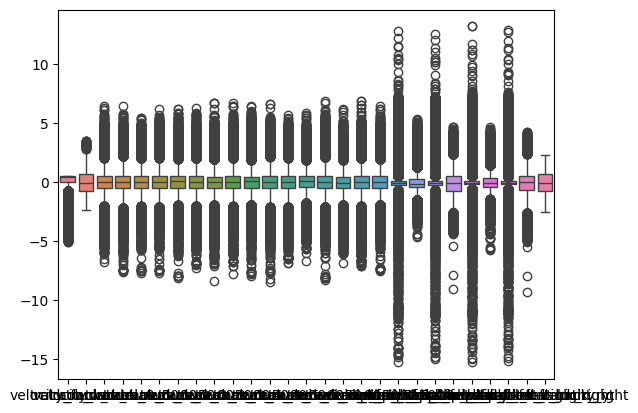

In [51]:
sns.boxplot(rollout_df)

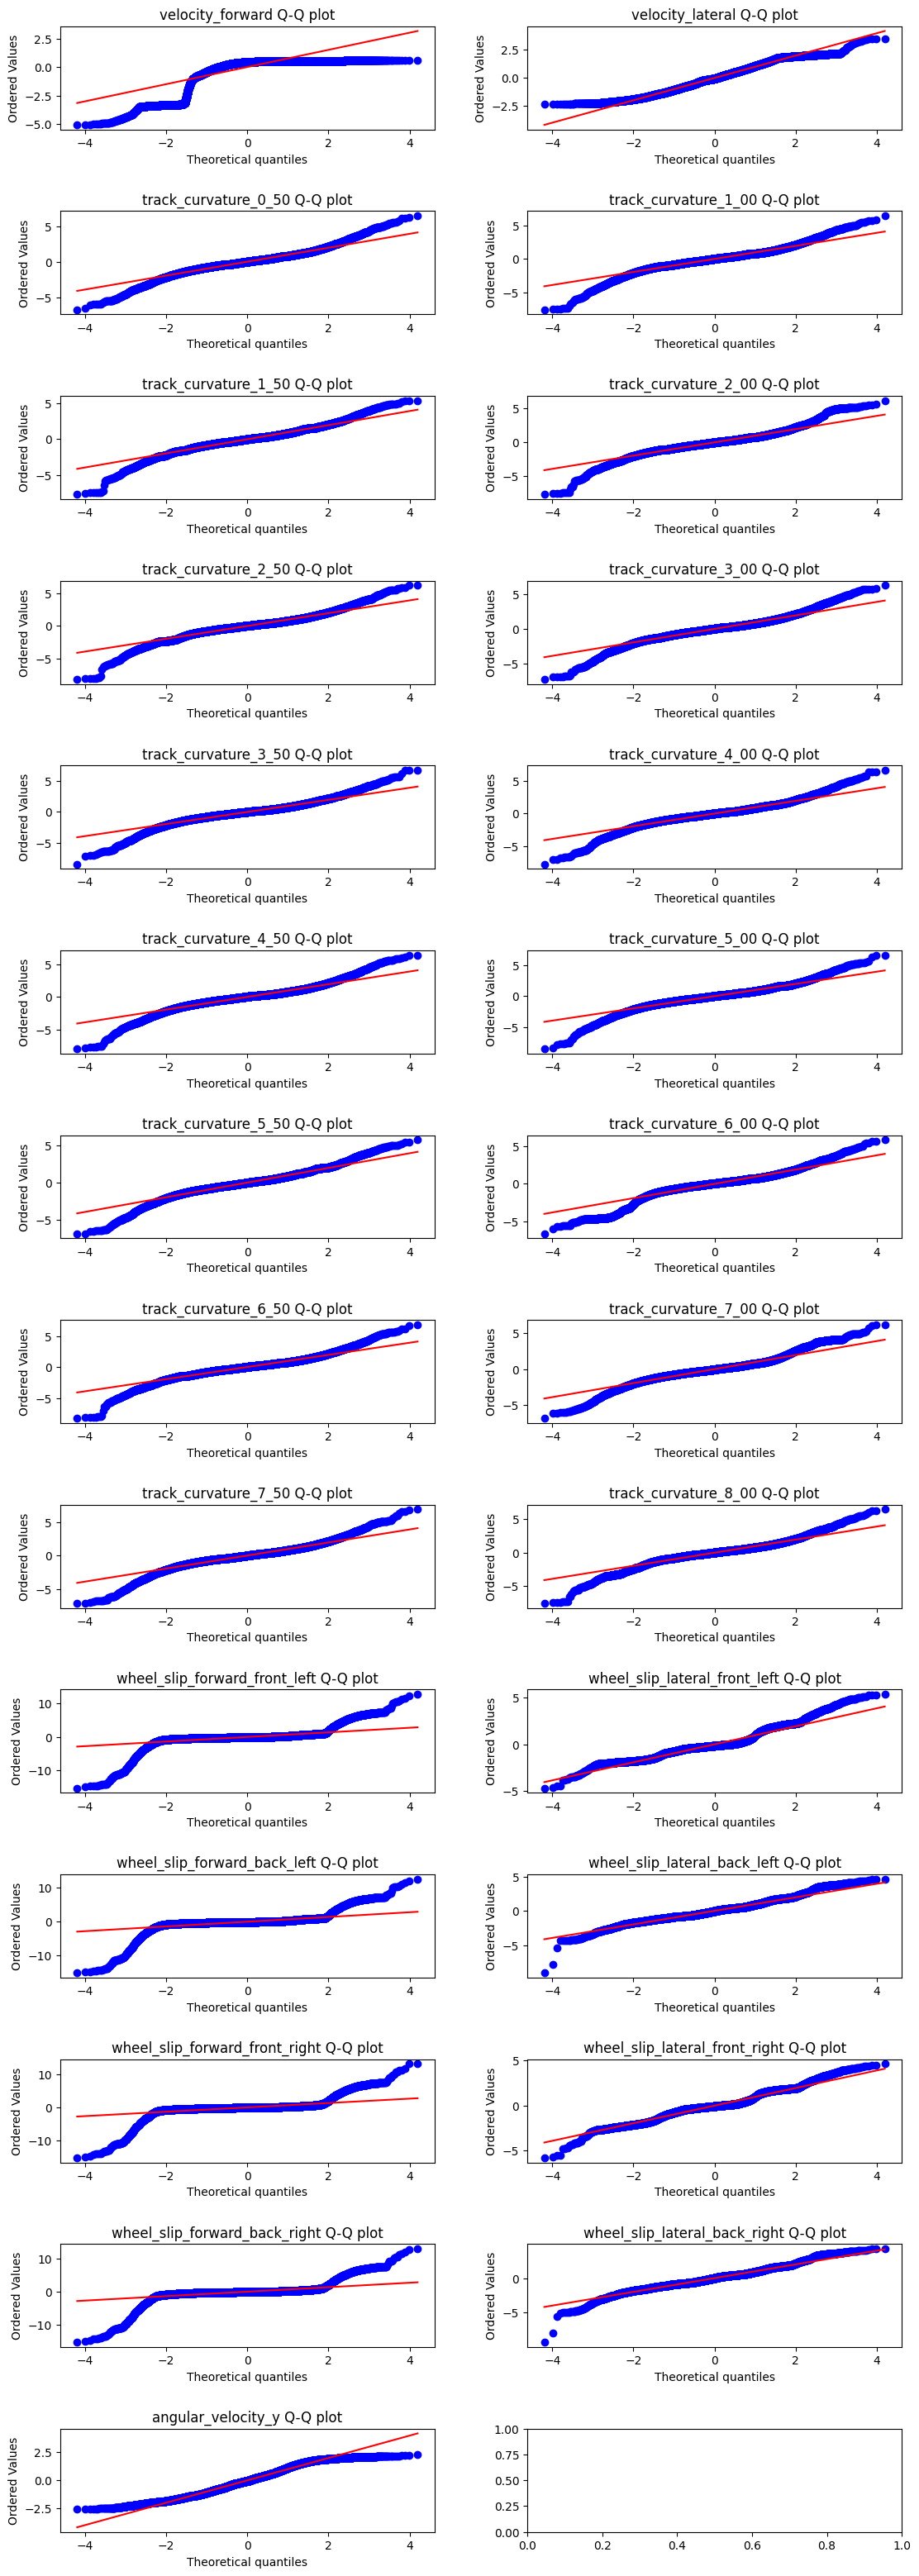

In [ ]:
fig, axs = plt.subplots(math.ceil(len(keys) / 3), 3, figsize=(12, 32))
fig.tight_layout(pad=5.0)
for key in keys:
    scipy.stats.probplot(rollout_df[key], dist="norm", plot=axs.flatten()[keys.index(key)])
    axs.flatten()[keys.index(key)].set_title(f"{key} Q-Q plot")